In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# Formats floats to display with 2 decimal places and suppresses scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Data Loading

In [2]:
trips = pd.read_csv('trips_count.csv')
trips

,starttime_date,count,trip_durration_sum,temperature_avg
0,2014-01-01,95,1020.18,19.48
1,2014-01-02,111,1292.85,16.83
2,2014-01-03,6,58.38,-5.63
3,2014-01-04,181,2001.35,30.01
4,2014-01-05,32,393.13,16.76
...,...,...,...,...
1453,2017-12-27,1117,10348.68,2.46
1454,2017-12-28,1267,12129.60,10.80
1455,2017-12-29,1049,10690.93,12.98
1456,2017-12-30,519,5054.87,3.66


Below we inspect data types and missing values.

In [3]:
trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458 entries, 0 to 1457
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   starttime_date      1458 non-null   object 
 1   count               1458 non-null   int64  
 2   trip_durration_sum  1458 non-null   float64
 3   temperature_avg     1458 non-null   float64
dtypes: float64(2), int64(1), object(1)
memory usage: 45.7+ KB


We convert date string column to true datetime objects (essential for time-series resampling/ordering).

In [4]:
trips['starttime_date'] = pd.to_datetime(trips['starttime_date'], format ='%Y-%m-%d')

In [5]:
trips_count = trips[['starttime_date','count']]

In [6]:
trips_count.head()

,starttime_date,count
0,2014-01-01,95
1,2014-01-02,111
2,2014-01-03,6
3,2014-01-04,181
4,2014-01-05,32


In [7]:
trips_count.tail(15)

,starttime_date,count
1443,2017-12-17,2653
1444,2017-12-18,5864
1445,2017-12-19,6914
1446,2017-12-20,3926
1447,2017-12-21,5404
1448,2017-12-22,4356
1449,2017-12-23,1600
1450,2017-12-24,386
1451,2017-12-25,226
1452,2017-12-26,737


## Train - test split

Splitting our dataset chronologically. We train our model on historical data up to December 31, 2016, and reserve the full year of 2017 to evaluate out-of-sample forecast accuracy.

Time series data must never be split randomly. To simulate a real-world forecasting environment, the model must train strictly on the past to predict an unseen future.

In [8]:
train = trips_count[trips_count['starttime_date'] < '2017-01-01']
train.tail()

,starttime_date,count
1088,2016-12-27,2521
1089,2016-12-28,3167
1090,2016-12-29,2858
1091,2016-12-30,2651
1092,2016-12-31,1669


In [9]:
train.shape

(1093, 2)

In [10]:
test = trips_count[trips_count['starttime_date'] >= '2017-01-01']
test.head()

,starttime_date,count
1093,2017-01-01,1365
1094,2017-01-02,1772
1095,2017-01-03,4431
1096,2017-01-04,3187
1097,2017-01-05,2833


In [11]:
test.shape

(365, 2)

In [12]:
# we will createan empty list to store the results of each experiment
experiment_logs = []

In [13]:
def log_experiment(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    
    experiment_logs.append({
        'Model': model_name, 
        'MAE': mae, 
        'RMSE': rmse, 
        'MAPE': mape
    })

# Prophet model


* **ARIMA** - Parametric, focuses on stationarity, lags, and error-term autocorrelation. Fails hard on multi-seasonality or missing data.

* **Prophet** - Non-parametric GAM(Generalised Additive Model) framework ($y(t) = g(t) + s(t) + h(t) + \epsilon_t$). It frames time as a set of curve-fitting/regression problems with Fourier series for seasonality.

## Baseline

### Preprocess the data

Prophet has a strict naming convention: 
- 'ds' (datestamp: date or datetime format) and 
- 'y' (numeric target to forecast)

Renaming our columns to match Prophet's strict internal schema requirements.

In [14]:
train.columns = ['ds', 'y']
test.columns = ['ds', 'y']

In [15]:
train.head()

,ds,y
0,2014-01-01,95
1,2014-01-02,111
2,2014-01-03,6
3,2014-01-04,181
4,2014-01-05,32


### Create the model

Importing Prophet and fitting it on the training set.

In [16]:
from prophet import Prophet

/opt/anaconda3/envs/Training/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Unlike traditional parametric models like ARIMA (which focus heavily on manually differencing data to achieve stationarity), Prophet acts as a Generalized Additive Model (GAM) that automatically decomposes time series data into trend curves, weekly seasonality, and yearly seasonality using Fourier series.

In [17]:
model = Prophet()

model.fit(train)

15:13:19 - cmdstanpy - INFO - Chain [1] start processing
15:13:19 - cmdstanpy - INFO - Chain [1] done processing


### Forecast

make_future_dataframe() method create a DataFrame with the future dates. It requires us to specify the number of future values to predict, and the frequency of the data.

In [18]:
future = model.make_future_dataframe(periods = 365, freq = 'D')

# 'MS', 'W'

In [19]:
future

,ds
0,2014-01-01
1,2014-01-02
2,2014-01-03
3,2014-01-04
4,2014-01-05
...,...
1453,2017-12-27
1454,2017-12-28
1455,2017-12-29
1456,2017-12-30


In [20]:
# Generate predictions for both historical and future dates
forecast = model.predict(future)

In [21]:
forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2014-01-01,4417.31,-1077.47,2329.18,4417.31,4417.31,-3839.30,-3839.30,-3839.30,813.01,813.01,813.01,-4652.30,-4652.30,-4652.30,0.00,0.00,0.00,578.01
1,2014-01-02,4416.88,-1177.79,2281.17,4416.88,4416.88,-3899.73,-3899.73,-3899.73,755.92,755.92,755.92,-4655.65,-4655.65,-4655.65,0.00,0.00,0.00,517.15
2,2014-01-03,4416.44,-1445.83,1985.20,4416.44,4416.44,-4159.41,-4159.41,-4159.41,483.89,483.89,483.89,-4643.29,-4643.29,-4643.29,0.00,0.00,0.00,257.04
3,2014-01-04,4416.01,-3493.05,-274.30,4416.01,4416.01,-6263.99,-6263.99,-6263.99,-1648.44,-1648.44,-1648.44,-4615.55,-4615.55,-4615.55,0.00,0.00,0.00,-1847.98
4,2014-01-05,4415.58,-3821.50,-317.65,4415.58,4415.58,-6492.26,-6492.26,-6492.26,-1919.22,-1919.22,-1919.22,-4573.05,-4573.05,-4573.05,0.00,0.00,0.00,-2076.69


In [22]:
forecast.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
1453,2017-12-27,7033.58,1743.69,5307.89,6484.86,7571.00,-3598.84,-3598.84,-3598.84,813.01,813.01,813.01,-4411.85,-4411.85,-4411.85,0.00,0.00,0.00,3434.74
1454,2017-12-28,7032.69,1530.75,5143.80,6481.72,7572.17,-3731.19,-3731.19,-3731.19,755.92,755.92,755.92,-4487.11,-4487.11,-4487.11,0.00,0.00,0.00,3301.50
1455,2017-12-29,7031.80,1152.27,4712.29,6477.99,7573.34,-4065.98,-4065.98,-4065.98,483.89,483.89,483.89,-4549.87,-4549.87,-4549.87,0.00,0.00,0.00,2965.82
1456,2017-12-30,7030.91,-1121.37,2636.74,6474.31,7574.29,-6247.36,-6247.36,-6247.36,-1648.44,-1648.44,-1648.44,-4598.92,-4598.92,-4598.92,0.00,0.00,0.00,783.56
1457,2017-12-31,7030.03,-1356.01,2360.95,6471.21,7573.57,-6552.49,-6552.49,-6552.49,-1919.22,-1919.22,-1919.22,-4633.28,-4633.28,-4633.28,0.00,0.00,0.00,477.53


* `yhat` - Final point prediction (sum of components).
* `yhat_lower` / `yhat_upper` - Uncertainty/prediction intervals.
* `trend`, `weekly`, `yearly`: The decomposed elements that mathematically sum up to yhat.

Plotting Prophet’s built-in forecast visualisation, overlaying our actual test values (in black dots) for direct visual comparison.

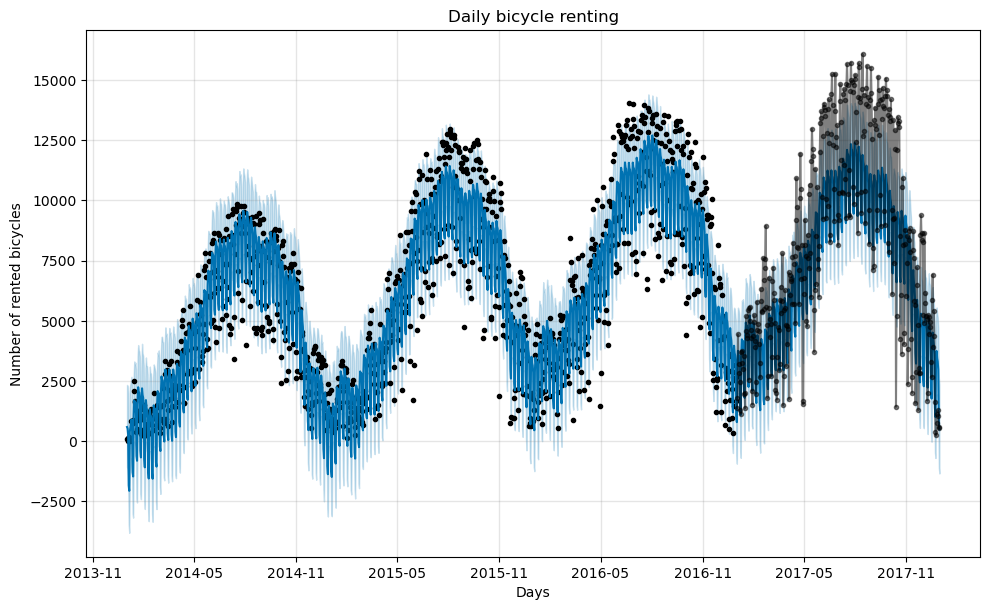

In [23]:
fig = model.plot(forecast, xlabel = 'Days', ylabel = 'Number of rented bicycles')
plt.title('Daily bicycle renting')
plt.plot(test['ds'], test['y'], color = 'black', marker = '.', alpha = 0.50)



The dark blue line represents Prophet's forecast (yhat), the light blue shaded region represents the uncertainty bounds, and the black dots show the real ground-truth data. Notice how well Prophet captures the overall scale and seasonal trajectory compared to basic ARIMA models.

The model does a great job showing the main seasonal trends, with more bikes in summer and fewer in winter. Still, the actual numbers sometimes jump or drop well outside the blue shaded uncertainty range. This suggests factors such as extreme weather that calendar dates alone don't capture.

### Evaluate

We slice tail 365 on yhat because make_future_dataframe(periods=365) appended exact horizon matching len(test). Alignment by index/date is critical here.

In [24]:
y_predicted = forecast['yhat'].iloc[-365:]

In [25]:
y_predicted

1093    779.40
1094   3180.55
1095   3746.29
1096   3557.30
1097   3545.39
         ...  
1453   3434.74
1454   3301.50
1455   2965.82
1456    783.56
1457    477.53
Name: yhat, Length: 365, dtype: float64

In [26]:
test['y']

1093    1365
1094    1772
1095    4431
1096    3187
1097    2833
        ... 
1453    1117
1454    1267
1455    1049
1456     519
1457     593
Name: y, Length: 365, dtype: int64

Log the experiment into our tracking table.

In [27]:
log_experiment('Prophet Baseline', test['y'], y_predicted)

In [28]:
pd.DataFrame(experiment_logs)

,Model,MAE,RMSE,MAPE
0,Prophet Baseline,1764.16,2209.94,33.61


An error of about 33% means our baseline model’s predictions are, on average, off by a third of the actual daily volume. Since this model uses only one variable and includes no tuning, holiday effects, or weather data, it’s a solid starting point. Next, we can add those features to help lower the MAPE.

The following method breaks down the aggregate yhat prediction into its individual components. For a baseline model, this typically generates three plots: overall trend, weekly seasonality, and yearly seasonality.

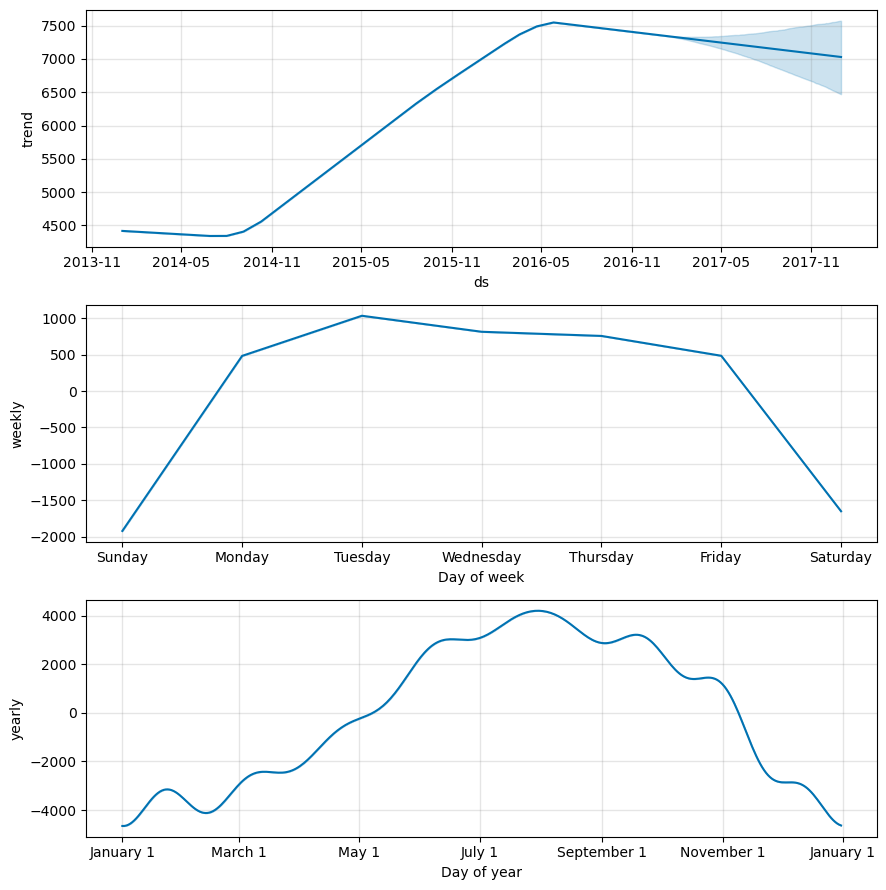

In [29]:
fig = model.plot_components(forecast)

**Trend Component**
The macro-level trajectory shows a massive growth phase from mid-2014 to mid-2016, during which the baseline for daily rentals nearly doubled from roughly 4,400 to over 7,500. After this peak, the trend flattens and slowly declines through 2017. The widening blue shaded area at the far right represents the confidence interval, or uncertainty bound, for the out-of-sample forecast.

**Weekly Seasonality**
This bike-share system is undeniably driven by weekday commuters, not weekend tourists. Rentals see a massive positive bump during the workweek—peaking on Tuesday with an additive effect of approximately +1,000 rentals—before completely plummeting on Saturdays and Sundays. The weekend drag pulls the baseline down by 1,500 to 2,000 trips.

**Yearly Seasonality**
Macro-environmental factors dictate the annual demand cycle. There is a massive structural trough in January and February where harsh winter conditions strip up to 4,000 rentals from the daily baseline. Conversely, demand rises steadily through spring, peaking in August.


### Task 1: Create a baseline model with Prophet on the sales data. 
- Split the data into the train set and test set(2018 year)
- Create the model and train it. Then forecast the future values.
- Compute the RMSE.
- Plot the components.

## The components of the Prophet model

<Axes: >

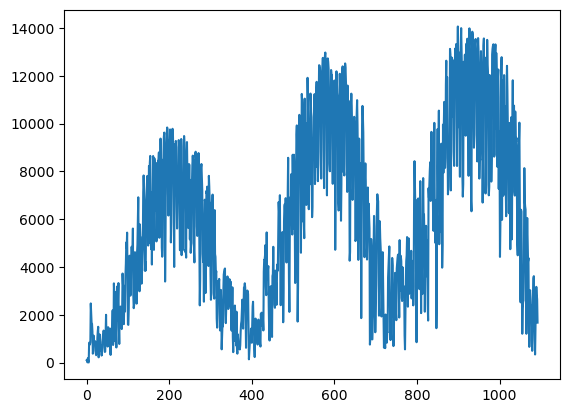

In [30]:
train['y'].plot()

The trend can be:
- **linear**('linear') - straight lines with positive or negative slope between the changepoints.
- **logistic**('logistic') - the trend is a logistic non linear function.

The seasonality and other predictors can be additive or multiplicative.

The additive model:
**y(t) = g(t) + s(t) + h(t) + r(t) + Et**

The multiplicative model:
**y(t) = g(t) x (1 + s(t)) + h(t) + r(t) + Et**


- y(t) - the prediction
- g(t) - the trend
- s(t) - the seasonality
- h(t) - the holidays
- r(t) - other predictors
- Et - the white noise term

The main parameters of the Prophet model are the following:
- **yearly_seasonality**: True or False if there is or there isn’t yearly seasonality. It can also be a number which represents the Fourier order with which the component is aproximated(default 10).
- **weekly_seasonality**: True or False if there is or there isn’t weekly seasonality. It can also be a number which represents the Fourier order with which the component is aproximated(default 3).
- **daily_seasonality**(if the data is hourly or more granular): True or False if there is or there isn’t daily seasonality. It can also be a number which represents the Fourier order with which the component is aproximated(default 4).
- **n_changepoints**: number of trend changepoints.
- **changepoints**: list of explicit changepoint dates, where trend changes are made.
- **changepoint_range**: percentage of the data where changepoints are infered.
- **changepoint_prior_scale**: the strength or possibility of trend change. The bigger the value, the higher the flexibility of the trend.
- **seasonality_prior_scale**: strength of the seasonality component or components. This value can be general for all the seasonalities or adjusted specifically for each of them.
- **holiday_prior_scale**: strength of the holiday component. 

## Fourier order

Prophet models seasonality using a partial Fourier series (combinations of sine and cosine waves) to approximate repeating patterns. Fourier orders dictate the "wiggliness" of the seasonal curve. A low order (like 3) creates a smooth, broad wave. A high order (like 20) allows the curve to sharply snap to rapid changes, but risks overfitting to random noise.

In [31]:
model = Prophet(seasonality_mode = 'multiplicative', 
                yearly_seasonality = 10)
model.fit(train)

15:13:20 - cmdstanpy - INFO - Chain [1] start processing
15:13:20 - cmdstanpy - INFO - Chain [1] done processing


In [32]:
future = model.make_future_dataframe(periods = 365, freq = 'D')
forecast = model.predict(future)

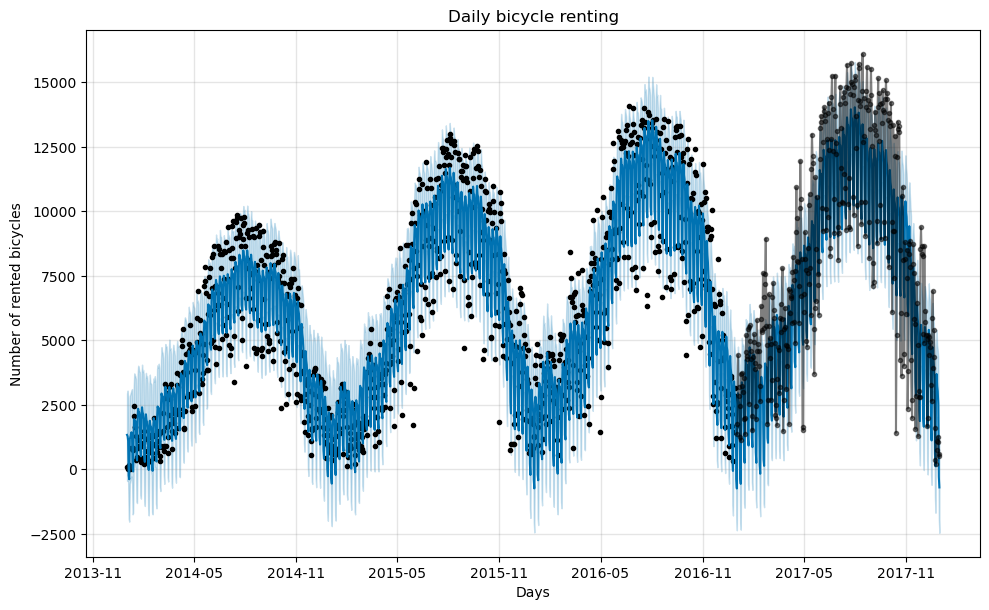

In [33]:
fig = model.plot(forecast, xlabel = 'Days', ylabel = 'Number of rented bicycles')
plt.title('Daily bicycle renting')
plt.plot(test['ds'], test['y'], color = 'black', marker = '.', alpha = 0.50)

In [34]:
y_predicted = forecast['yhat'].iloc[-365:]

In [35]:
root_mean_squared_error(test['y'], y_predicted)


1976.0197316508525

In [36]:
log_experiment('Yearly Seasonal', test['y'], y_predicted)
pd.DataFrame(experiment_logs)

,Model,MAE,RMSE,MAPE
0,Prophet Baseline,1764.16,2209.94,33.61
1,Yearly Seasonal,1573.01,1976.02,35.22


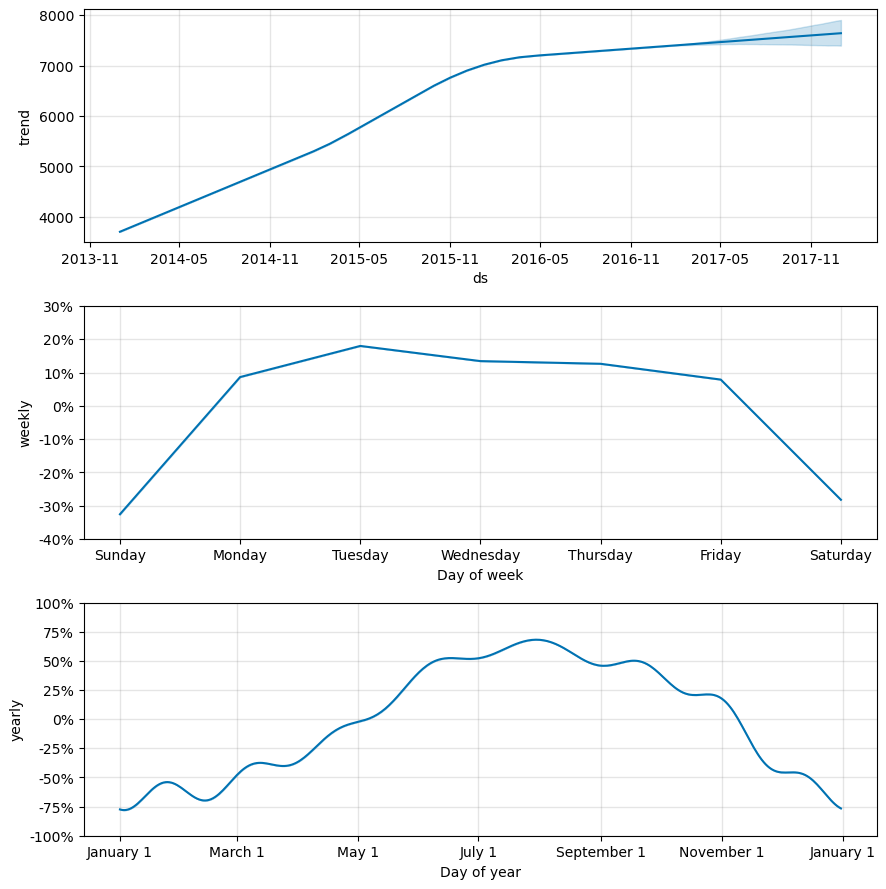

In [37]:
fig = model.plot_components(forecast)

## Seasonal analysis

- annual seasonality
- monthly seasonality
- weekly seasonality
- other seasonalities

In [38]:
train.head()

,ds,y
0,2014-01-01,95
1,2014-01-02,111
2,2014-01-03,6
3,2014-01-04,181
4,2014-01-05,32


In [39]:
train['day'] = train['ds'].dt.dayofweek

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/1338167137.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['day'] = train['ds'].dt.dayofweek


In [40]:
train.head()

,ds,y,day
0,2014-01-01,95,2
1,2014-01-02,111,3
2,2014-01-03,6,4
3,2014-01-04,181,5
4,2014-01-05,32,6


<Axes: xlabel='ds', ylabel='y'>

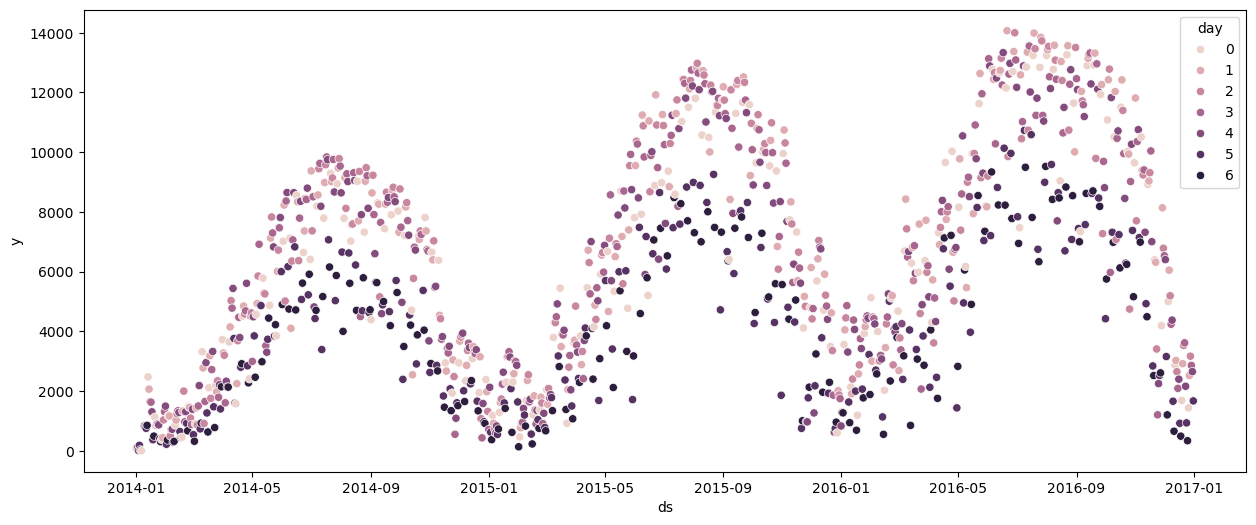

In [41]:
fig, ax = plt.subplots(figsize=(15,6))
day_order = range(6)
sns.scatterplot(x="ds", 
                y="y",
                hue="day",
                hue_order=day_order,
                data=train, 
                ax=ax)

# 0-Monday --- 6-Sunday

More trips occur on weekdays than on weekends.

The data also indicates a significant difference in the number of trips between weekdays and weekends during the summer.

However, in the winter of 2015, weekday and weekend trips were similar. In 2016, weekday trips increased more.

In [42]:
train.groupby(train['day'])['y'].sum()

day
0    1009628
1    1094938
2    1061802
3    1054091
4    1005208
5     677370
6     634508
Name: y, dtype: int64

In [43]:
train['year'] = train['ds'].dt.year

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/797243796.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['year'] = train['ds'].dt.year


In [44]:
train['month'] = train['ds'].dt.month

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/1733627913.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['month'] = train['ds'].dt.month


In [45]:
df_ym = train.groupby(['year', 'month'])['y'].sum().reset_index()

In [46]:
df_ym.head()

,year,month,y
0,2014,1,23617
1,2014,2,26221
2,2014,3,56020
3,2014,4,105428
4,2014,5,159957


In [47]:
df_ym.tail()

,year,month,y
31,2016,8,345086
32,2016,9,319003
33,2016,10,275132
34,2016,11,203500
35,2016,12,88363


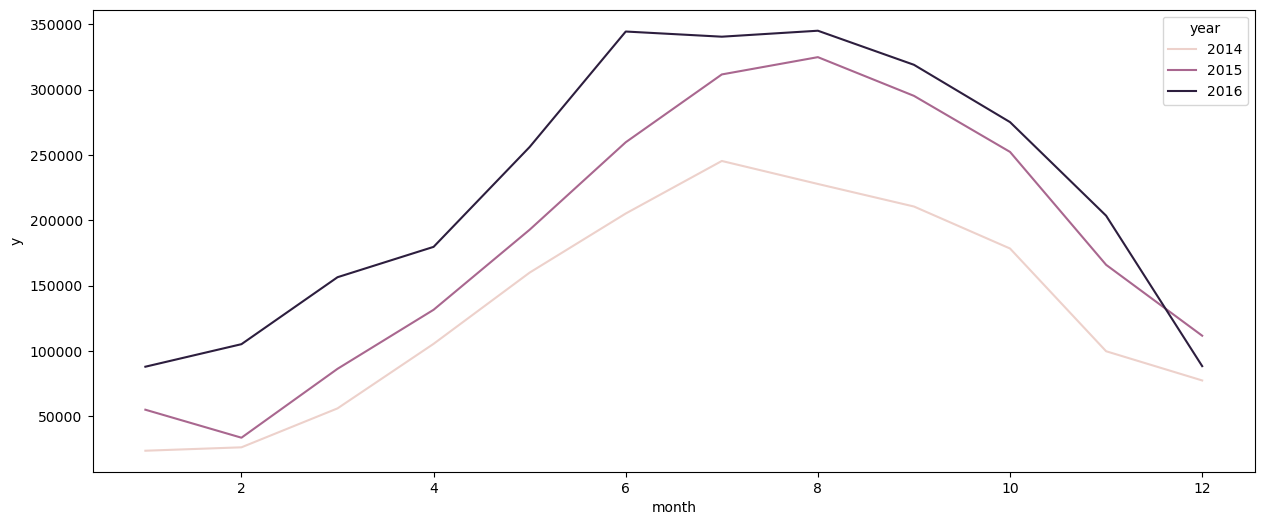

In [48]:
fig, ax = plt.subplots(figsize=(15, 6))
ax = sns.lineplot(x = df_ym['month'], y = df_ym['y'], hue=df_ym['year'], ax=ax)

In the plot above, we see a decrease in the winter months and an increase in the summer months. We also see a growing trend from year to year.

- The data show global annual and monthly seasonality. 

- The weekly seasonality changes after the winter of 2015(we can use the conditional seasonality)



To do:

- Load the holidays

- Define the conditional seasonality

- Use other predictors

## Conditional seasonality

Prophet asks for two comlementary boolean columns, one that is True if the condition is met and False elsewhere, and a second column that is the opposite.
We will consider the 1st of February 2016 a change in the seasonality.

In [49]:
train['weekly_before_feb_2016'] = [True if dt < pd.to_datetime('2016-02-01') else False for dt in train['ds']]
train['weekly_after_feb_2016'] = [False if dt < pd.to_datetime('2016-02-01') else True for dt in train['ds']]

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/937921082.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['weekly_before_feb_2016'] = [True if dt < pd.to_datetime('2016-02-01') else False for dt in train['ds']]
/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/937921082.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['weekly_after_feb_2016'] = [False if dt < pd.to_datetime('2016-02-01') else True for dt in train['ds']]


In [50]:
train.columns

Index(['ds', 'y', 'day', 'year', 'month', 'weekly_before_feb_2016',
       'weekly_after_feb_2016'],
      dtype='object')

We will create boolean masks to split the timeline.

The EDA revealed that weekend vs. weekday riding patterns fundamentally changed after winter 2015. If user behavior shifts permanently, a single weekly seasonality curve will fail. By passing these boolean columns into Prophet, the model learns two completely distinct weekly patterns for the two different eras.

In [51]:
test['weekly_before_feb_2016'] = [True if dt < pd.to_datetime('2016-02-01') else False for dt in test['ds']]
test['weekly_after_feb_2016'] = [False if dt < pd.to_datetime('2016-02-01') else True for dt in test['ds']]

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/3221279510.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['weekly_before_feb_2016'] = [True if dt < pd.to_datetime('2016-02-01') else False for dt in test['ds']]
/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/3221279510.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['weekly_after_feb_2016'] = [False if dt < pd.to_datetime('2016-02-01') else True for dt in test['ds']]


## Other regressors

In [52]:
trips

,starttime_date,count,trip_durration_sum,temperature_avg
0,2014-01-01,95,1020.18,19.48
1,2014-01-02,111,1292.85,16.83
2,2014-01-03,6,58.38,-5.63
3,2014-01-04,181,2001.35,30.01
4,2014-01-05,32,393.13,16.76
...,...,...,...,...
1453,2017-12-27,1117,10348.68,2.46
1454,2017-12-28,1267,12129.60,10.80
1455,2017-12-29,1049,10690.93,12.98
1456,2017-12-30,519,5054.87,3.66


In [53]:
print(trips['temperature_avg'].mean())
print(trips['temperature_avg'].std())

53.101448172284215
21.002911717760163


In [54]:
trips[['count','temperature_avg']].corr()

,count,temperature_avg
count,1.00,0.78
temperature_avg,0.78,1.00


## Building the model

### Preprocessing

In [55]:
temp_train = trips['temperature_avg'][trips['starttime_date'] < '2017-01-01']
temp_test = trips['temperature_avg'][trips['starttime_date'] >= '2017-01-01']

In [56]:
train.drop(columns=['day', 'year', 'month'], inplace=True)

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/904760310.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train.drop(columns=['day', 'year', 'month'], inplace=True)


In [57]:
train['temperature_avg'] = temp_train.values

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/1876565737.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['temperature_avg'] = temp_train.values


In [58]:
train

,ds,y,weekly_before_feb_2016,weekly_after_feb_2016,temperature_avg
0,2014-01-01,95,True,False,19.48
1,2014-01-02,111,True,False,16.83
2,2014-01-03,6,True,False,-5.63
3,2014-01-04,181,True,False,30.01
4,2014-01-05,32,True,False,16.76
...,...,...,...,...,...
1088,2016-12-27,2521,False,True,26.29
1089,2016-12-28,3167,False,True,36.98
1090,2016-12-29,2858,False,True,32.46
1091,2016-12-30,2651,False,True,29.37


In [59]:
test['temperature_avg'] = temp_test.values

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/3218206519.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['temperature_avg'] = temp_test.values


In [60]:
test 

,ds,y,weekly_before_feb_2016,weekly_after_feb_2016,temperature_avg
1093,2017-01-01,1365,False,True,33.03
1094,2017-01-02,1772,False,True,38.04
1095,2017-01-03,4431,False,True,36.15
1096,2017-01-04,3187,False,True,12.77
1097,2017-01-05,2833,False,True,8.86
...,...,...,...,...,...
1453,2017-12-27,1117,False,True,2.46
1454,2017-12-28,1267,False,True,10.80
1455,2017-12-29,1049,False,True,12.98
1456,2017-12-30,519,False,True,3.66


### The model

We will turn off all default seasonalities and rebuild the model from scratch with custom parameters. We add US holidays to handle Thanksgiving/Christmas dips, apply our conditional weekly seasonalities, and inject average temperature as a continuous regressor.

In [61]:
model = Prophet(seasonality_mode = 'multiplicative',
               growth = 'linear',
               yearly_seasonality = False,
                weekly_seasonality = False,
                daily_seasonality = False
               )

# 'additive' - by default

#### Add the holidays

To add the holidays to the model we need to: 
1. create the model
2. add model.add_country_holidays(country_name = 'US')
3. Fit the model
4. All the usual steps

In [62]:
model.add_country_holidays(country_name = 'US')

#### Seasonalities

In [63]:
model.add_seasonality(name = 'yearly', 
                      period = 365, 
                      fourier_order = 10)

name - A string label for your custom component.

period - The number of days in one full cycle (e.g., 30.5 for monthly, 91.25 for quarterly).

fourier_order - The number of sine/cosine pairs used to fit the curve.

When deciding what order to set, keep the balance between flexibility and noise in mind:

**Lower Fourier Order (e.g., 2 to 5):**

- Produces a very smooth, gradual curve.

- Ideal if your seasonal pattern is stable, simple, and slow-moving.

- Highly resistant to overfitting noise.

**Higher Fourier Order (e.g., 15 to 20+):**

- Allows the model to fit sharp, fast-changing cycles and high-frequency details.

- Risky because it can easily start memorizing random noise or anomalies in your training history rather than true seasonal behavior, leading to poor test predictions (overfitting).

Always start with Prophet's defaults or a low order (like 5 for monthly). Only increase the order if you notice the model is missing sharp seasonal peaks or troughs in your historical plots.

Fourier series simulation online: https://www.falstad.com/fourier/

In [64]:
model.add_seasonality(name = 'monthly', 
                      period = 31, 
                      fourier_order = 5)

In [65]:
train.columns

Index(['ds', 'y', 'weekly_before_feb_2016', 'weekly_after_feb_2016',
       'temperature_avg'],
      dtype='object')

In [66]:
model.add_seasonality(name = 'weekly_before_feb_2016', 
                      period = 7, 
                      fourier_order = 3,
                     condition_name = 'weekly_before_feb_2016')

In [67]:
model.add_seasonality(name = 'weekly_after_feb_2016', 
                      period = 7, 
                      fourier_order = 3,
                     condition_name = 'weekly_after_feb_2016')

#### Add other predictors

In [68]:
model.add_regressor('temperature_avg')

#### Fit the model

In [69]:
model.fit(train)

15:13:22 - cmdstanpy - INFO - Chain [1] start processing
15:13:22 - cmdstanpy - INFO - Chain [1] done processing


#### Predict

When creating the future dataframe for this model, we must explicitly copy the boolean conditions and temperature_avg values from the test set into it. Prophet cannot predict the future without future values for its extra regressors.

In [70]:
future = model.make_future_dataframe(periods = 365, freq = 'D')

In [71]:
future

,ds
0,2014-01-01
1,2014-01-02
2,2014-01-03
3,2014-01-04
4,2014-01-05
...,...
1453,2017-12-27
1454,2017-12-28
1455,2017-12-29
1456,2017-12-30


In [72]:
future[['weekly_before_feb_2016',
        'weekly_after_feb_2016', 
        'temperature_avg']] = pd.concat([train[['weekly_before_feb_2016', 'weekly_after_feb_2016', 'temperature_avg']],
                                                test[['weekly_before_feb_2016', 'weekly_after_feb_2016', 'temperature_avg']]])

In [73]:
future

,ds,weekly_before_feb_2016,weekly_after_feb_2016,temperature_avg
0,2014-01-01,True,False,19.48
1,2014-01-02,True,False,16.83
2,2014-01-03,True,False,-5.63
3,2014-01-04,True,False,30.01
4,2014-01-05,True,False,16.76
...,...,...,...,...
1453,2017-12-27,False,True,2.46
1454,2017-12-28,False,True,10.80
1455,2017-12-29,False,True,12.98
1456,2017-12-30,False,True,3.66


In [74]:
forecast = model.predict(future)

In [75]:
forecast.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,Christmas Day,Christmas Day_lower,Christmas Day_upper,Christmas Day (observed),...,weekly_before_feb_2016,weekly_before_feb_2016_lower,weekly_before_feb_2016_upper,yearly,yearly_lower,yearly_upper,additive_terms,additive_terms_lower,additive_terms_upper,yhat
1453,2017-12-27,7563.10,-880.54,1836.77,7199.74,7943.23,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,-0.40,-0.40,-0.40,0.00,0.00,0.00,468.71
1454,2017-12-28,7563.88,376.69,3010.67,7198.97,7945.38,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,-0.40,-0.40,-0.40,0.00,0.00,0.00,1705.97
1455,2017-12-29,7564.66,382.85,3164.39,7197.52,7947.46,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,-0.40,-0.40,-0.40,0.00,0.00,0.00,1762.83
1456,2017-12-30,7565.44,-3508.17,-728.85,7196.08,7949.53,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,-0.40,-0.40,-0.40,0.00,0.00,0.00,-2138.86
1457,2017-12-31,7566.22,-3491.28,-729.30,7195.52,7951.59,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,-0.40,-0.40,-0.40,0.00,0.00,0.00,-2187.04


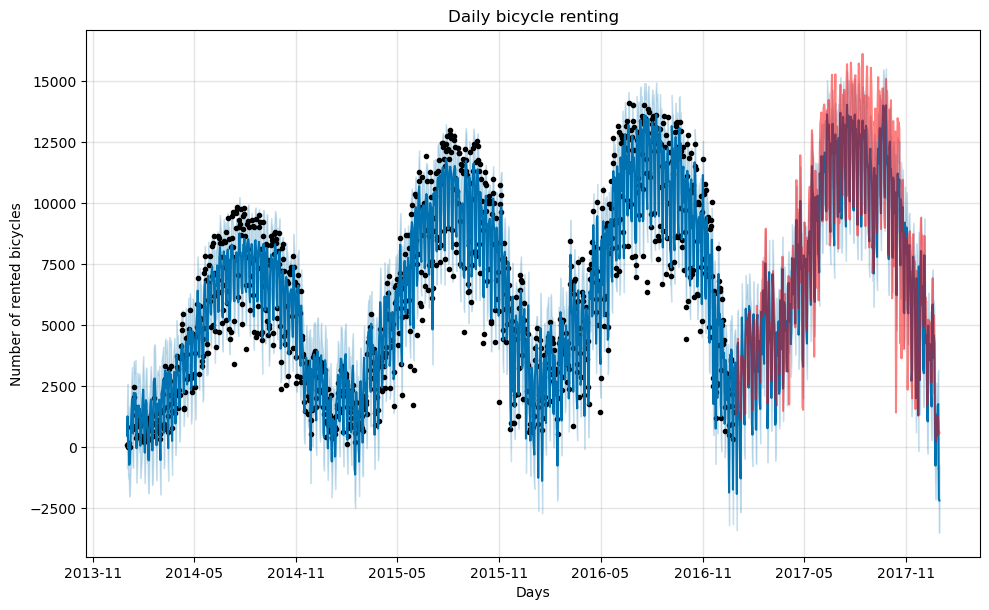

In [76]:
fig = model.plot(forecast, xlabel = 'Days', ylabel = 'Number of rented bicycles')
plt.title('Daily bicycle renting')
plt.plot(test['ds'], test['y'], color = 'red', alpha = 0.5)

In [77]:
y_predicted = forecast['yhat'].iloc[-365:]

In [78]:
root_mean_squared_error(test['y'], y_predicted)

1592.4268638485726

In [79]:
log_experiment('Custom Seasonal and Other Features', test['y'], y_predicted)
pd.DataFrame(experiment_logs)

,Model,MAE,RMSE,MAPE
0,Prophet Baseline,1764.16,2209.94,33.61
1,Yearly Seasonal,1573.01,1976.02,35.22
2,Custom Seasonal and Other Features,1279.19,1592.43,27.32


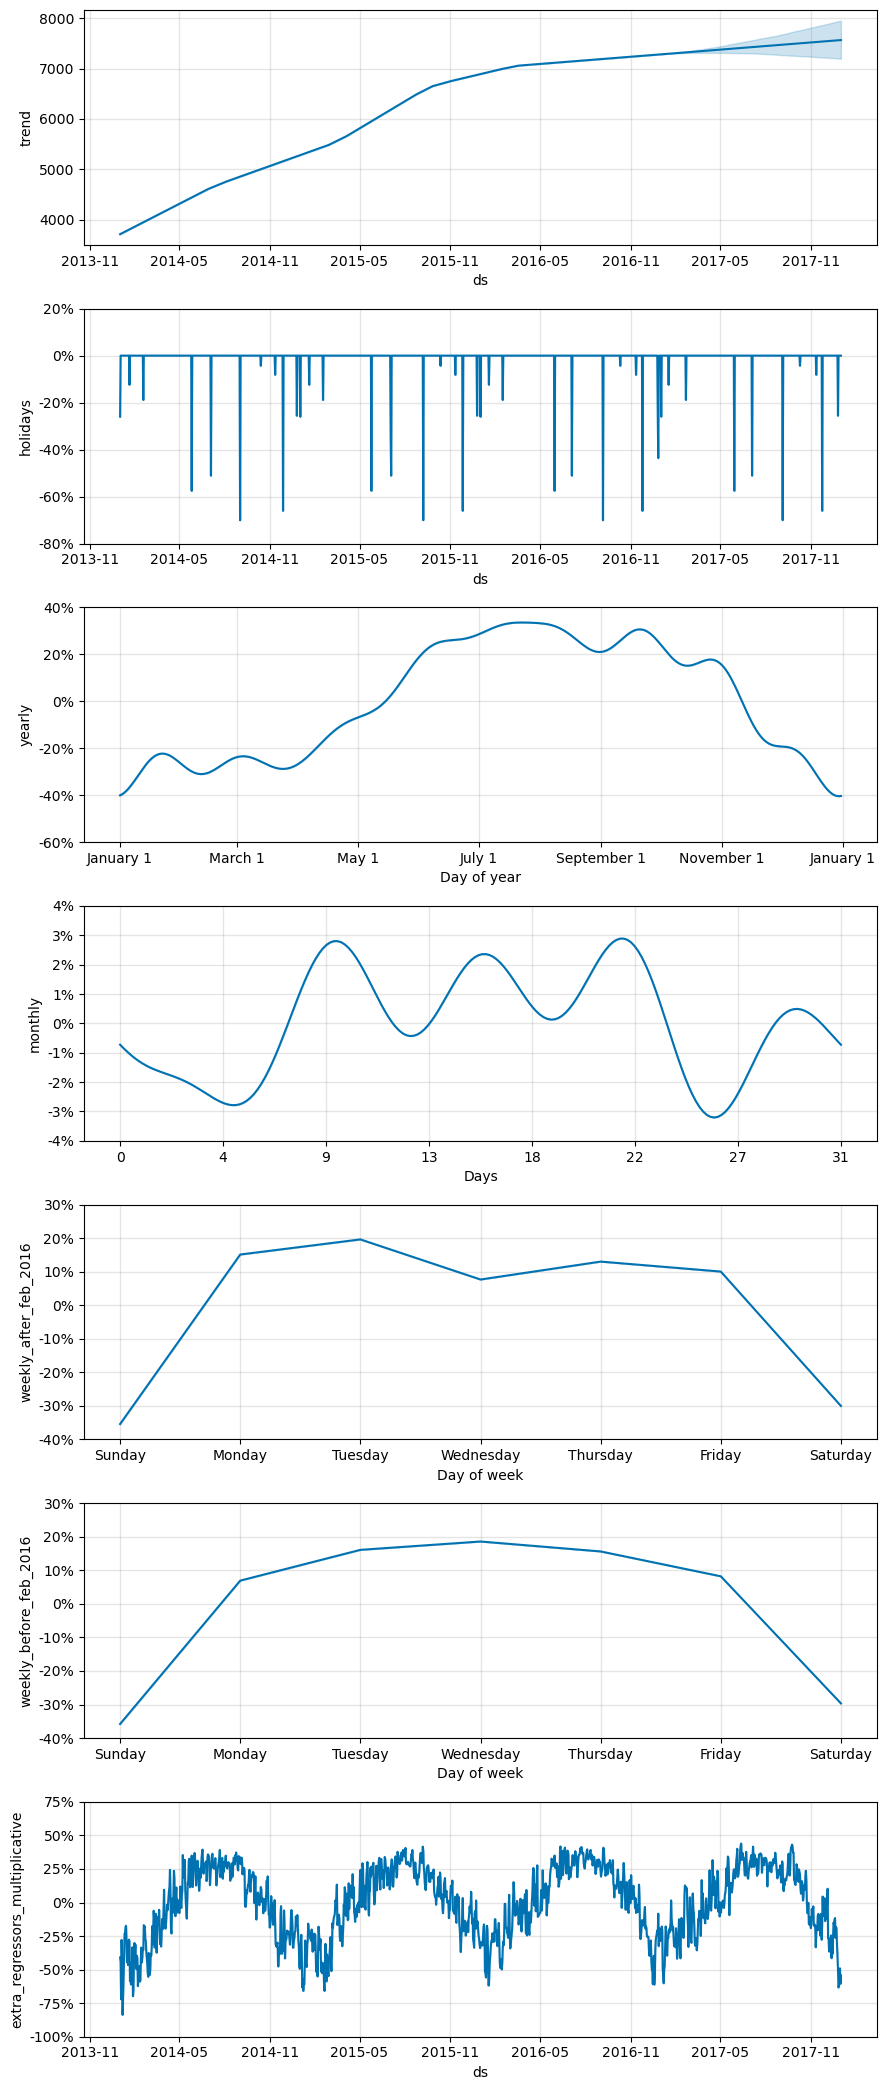

In [80]:
fig = model.plot_components(forecast)

### Task 2: Predict the daily sales. 
- Create a model and insert the holidays in the model. 
- Set up the seasonalities
- Add other regressors
- Evaluate the model
- Visualise the predictions and the model components

# Find the best hyperparameter

In [81]:
from sklearn.model_selection import ParameterGrid

We will set up a brute-force search over 100 possible combinations of Fourier orders and seasonality modes to find the mathematically optimal configuration.

In [82]:
params_grid = {
    'yearly_seasonality': range(10,15),
    'weekly_seasonality': range(5,15),
    'seasonality_mode': ['multiplicative', 'additive']
    } 
# # 'additive' - by default
grid = ParameterGrid(params_grid) 
grid
print([p for p in grid])

[{'seasonality_mode': 'multiplicative', 'weekly_seasonality': 5, 'yearly_seasonality': 10}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 5, 'yearly_seasonality': 11}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 5, 'yearly_seasonality': 12}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 5, 'yearly_seasonality': 13}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 5, 'yearly_seasonality': 14}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 6, 'yearly_seasonality': 10}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 6, 'yearly_seasonality': 11}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 6, 'yearly_seasonality': 12}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 6, 'yearly_seasonality': 13}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 6, 'yearly_seasonality': 14}, {'seasonality_mode': 'multiplicative', 'weekly_seasonality': 7, 'yearly_seasonality': 10}

In [83]:
results = pd.DataFrame(grid)

rmse_list = []
for p in grid:
    m =Prophet(**p, growth = 'linear')
    m.fit(train[['ds', 'y']])
    future = m.make_future_dataframe(periods = 365, freq = 'D')
    forecast = m.predict(future)
    y_predicted = forecast['yhat'].iloc[-365:]
    rmse = root_mean_squared_error(test['y'], y_predicted)
    rmse_list.append(rmse)
    
results['rmse'] = rmse_list

15:13:23 - cmdstanpy - INFO - Chain [1] start processing
15:13:23 - cmdstanpy - INFO - Chain [1] done processing
15:13:23 - cmdstanpy - INFO - Chain [1] start processing
15:13:23 - cmdstanpy - INFO - Chain [1] done processing
15:13:23 - cmdstanpy - INFO - Chain [1] start processing
15:13:23 - cmdstanpy - INFO - Chain [1] done processing
15:13:23 - cmdstanpy - INFO - Chain [1] start processing
15:13:23 - cmdstanpy - INFO - Chain [1] done processing
15:13:23 - cmdstanpy - INFO - Chain [1] start processing
15:13:24 - cmdstanpy - INFO - Chain [1] done processing
15:13:24 - cmdstanpy - INFO - Chain [1] start processing
15:13:24 - cmdstanpy - INFO - Chain [1] done processing
15:13:24 - cmdstanpy - INFO - Chain [1] start processing
15:13:24 - cmdstanpy - INFO - Chain [1] done processing
15:13:24 - cmdstanpy - INFO - Chain [1] start processing
15:13:24 - cmdstanpy - INFO - Chain [1] done processing
15:13:24 - cmdstanpy - INFO - Chain [1] start processing
15:13:24 - cmdstanpy - INFO - Chain [1]

In [84]:
results

,seasonality_mode,weekly_seasonality,yearly_seasonality,rmse
0,multiplicative,5,10,1979.03
1,multiplicative,5,11,1990.23
2,multiplicative,5,12,1984.39
3,multiplicative,5,13,1993.05
4,multiplicative,5,14,1974.85
...,...,...,...,...
95,additive,14,10,2174.79
96,additive,14,11,2207.91
97,additive,14,12,2198.23
98,additive,14,13,2183.39


In [85]:
results.sort_values(by = 'rmse')

,seasonality_mode,weekly_seasonality,yearly_seasonality,rmse
34,multiplicative,11,14,1900.81
44,multiplicative,13,14,1902.68
39,multiplicative,12,14,1903.22
29,multiplicative,10,14,1903.36
14,multiplicative,7,14,1903.46
...,...,...,...,...
60,additive,7,10,2222.65
50,additive,5,10,2231.12
90,additive,13,10,2232.77
70,additive,9,10,2236.09


## Cross Validation

In [86]:
from prophet.diagnostics import cross_validation

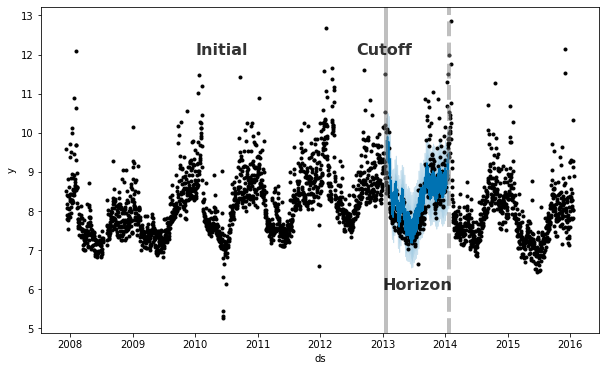

- initial - is the first training period
- horizon - is the length of time to evaluate the forecast over
- period - is the amount of time between each fold
- cutoff - is the date where the horizon will begin

The cross_validation function executes rolling-origin cross-validation. It trains on the first 365 days, predicts 60 days out, then shifts the training window forward by 30 days and repeats the process until it runs out of historical data.

In [87]:
cv_results = cross_validation( model = model, 
                              initial='365 days', 
                              period='30 days', 
                              horizon = '60 day')

# The initial model will be trained on the first 365 days of data. 
# It will forecast the next 60 days of data (because horizon is set to 60). 
# The model will then train on the initial period + the period (365 + 30 days in this case) 
# and forecast the next 60 days. It will continued like this, 
# adding another 30 days to the training data 
# and then forecasting for the next 60 until there is no longer enough data to do this.

  0%|          | 0/23 [00:00<?, ?it/s]15:13:47 - cmdstanpy - INFO - Chain [1] start processing
15:13:47 - cmdstanpy - INFO - Chain [1] done processing
  4%|▍         | 1/23 [00:00<00:02,  9.31it/s]15:13:48 - cmdstanpy - INFO - Chain [1] start processing
15:13:48 - cmdstanpy - INFO - Chain [1] done processing
  9%|▊         | 2/23 [00:00<00:02,  8.37it/s]15:13:48 - cmdstanpy - INFO - Chain [1] start processing
15:13:48 - cmdstanpy - INFO - Chain [1] done processing
 13%|█▎        | 3/23 [00:00<00:02,  8.99it/s]15:13:48 - cmdstanpy - INFO - Chain [1] start processing
15:13:48 - cmdstanpy - INFO - Chain [1] done processing
 17%|█▋        | 4/23 [00:00<00:02,  9.15it/s]15:13:48 - cmdstanpy - INFO - Chain [1] start processing
15:13:48 - cmdstanpy - INFO - Chain [1] done processing
15:13:48 - cmdstanpy - INFO - Chain [1] start processing
15:13:48 - cmdstanpy - INFO - Chain [1] done processing
 26%|██▌       | 6/23 [00:00<00:01,  9.35it/s]15:13:48 - cmdstanpy - INFO - Chain [1] start processi

In [88]:
cv_results

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2015-01-12,2269.36,1280.82,3209.47,1287,2015-01-11
1,2015-01-13,2218.63,1171.67,3182.82,1620,2015-01-11
2,2015-01-14,2193.29,1200.45,3184.57,1734,2015-01-11
3,2015-01-15,3250.56,2239.42,4236.35,2231,2015-01-11
4,2015-01-16,3376.02,2365.40,4358.66,2630,2015-01-11
...,...,...,...,...,...,...
1375,2016-12-27,3325.62,2040.06,4710.21,2521,2016-11-01
1376,2016-12-28,3449.17,2074.95,4688.20,3167,2016-11-01
1377,2016-12-29,3472.98,2218.36,4791.80,2858,2016-11-01
1378,2016-12-30,3172.18,1707.40,4576.24,2651,2016-11-01


This table logs every individual prediction the model made during its simulated historical forecasts.   
- **cutoff**: The "simulated present day." The model was trained using only data occurring before this specific date.   
- **ds**: The target date being predicted.   
- **yhat**: The model's prediction for that specific ds.   
- **yhat_lower & yhat_upper**: The lower and upper bounds of the uncertainty interval.   
- **y**: The actual ground-truth value that occurred on that date.  

Typically, forecast error increases as the prediction horizon gets longer. This is normal, as a model is less certain about events further into the future.

If the error remains relatively flat or even decreases at longer horizons, it might suggest your model is mostly capturing long-term trend and seasonality well, but is less accurate with short-term noise.

In [89]:
cv_results['cutoff'].value_counts()

cutoff
2015-01-11    60
2016-01-06    60
2016-10-02    60
2016-09-02    60
2016-08-03    60
2016-07-04    60
2016-06-04    60
2016-05-05    60
2016-04-05    60
2016-03-06    60
2016-02-05    60
2015-12-07    60
2015-02-10    60
2015-11-07    60
2015-10-08    60
2015-09-08    60
2015-08-09    60
2015-07-10    60
2015-06-10    60
2015-05-11    60
2015-04-11    60
2015-03-12    60
2016-11-01    60
Name: count, dtype: int64

In [90]:
cv_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1380 entries, 0 to 1379
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ds          1380 non-null   datetime64[ns]
 1   yhat        1380 non-null   float64       
 2   yhat_lower  1380 non-null   float64       
 3   yhat_upper  1380 non-null   float64       
 4   y           1380 non-null   int64         
 5   cutoff      1380 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(3), int64(1)
memory usage: 64.8 KB


In [91]:
cv_results['errors'] = cv_results['y'] - cv_results['yhat']
cv_results

,ds,yhat,yhat_lower,yhat_upper,y,cutoff,errors
0,2015-01-12,2269.36,1280.82,3209.47,1287,2015-01-11,-982.36
1,2015-01-13,2218.63,1171.67,3182.82,1620,2015-01-11,-598.63
2,2015-01-14,2193.29,1200.45,3184.57,1734,2015-01-11,-459.29
3,2015-01-15,3250.56,2239.42,4236.35,2231,2015-01-11,-1019.56
4,2015-01-16,3376.02,2365.40,4358.66,2630,2015-01-11,-746.02
...,...,...,...,...,...,...,...
1375,2016-12-27,3325.62,2040.06,4710.21,2521,2016-11-01,-804.62
1376,2016-12-28,3449.17,2074.95,4688.20,3167,2016-11-01,-282.17
1377,2016-12-29,3472.98,2218.36,4791.80,2858,2016-11-01,-614.98
1378,2016-12-30,3172.18,1707.40,4576.24,2651,2016-11-01,-521.18


In [92]:
from prophet.diagnostics import performance_metrics

Prophet takes the raw cv_results table, groups the predictions by their forecast horizon, and calculates rolling averages of various error metrics. It pools all the raw errors from all models for a specific horizon window and calculates the metric directly from that pooled data.

- **horizon**: This shows how far ahead the prediction goes, from 6 days up to 60 days. By default, the rolling window covers 10% of the total forecast horizon. For example, if the horizon is 60 days, the forecast includes values for days 1 to 6. If the horizon is 7 days, it covers days 2 to 7, and so on.  
- **rmse & mae**: Absolute error metrics. RMSE penalises large outliers heavily, while MAE gives a straightforward average of how many units (bicycles) the forecast missed by.   
- **mape** (Mean Absolute Percentage Error): The percentage by which the prediction missed the actual value.   
- **mdape** (Median Absolute Percentage Error): The median of all the percentage errors for a given horizon window. It is superior to MAPE when our dataset contains extreme, unpredictable outliers.
- **smape** (Symmetric Mean Absolute Percentage Error): SMAPE puts the average of the actual and predicted values in the denominator. Used when the data fluctuates heavily or frequently approaches zero.
- **coverage**: The percentage of time the actual y value fell within the yhat_lower and yhat_upper uncertainty intervals.

MAPE vs SMAPE: https://towardsdatascience.com/choosing-the-correct-error-metric-mape-vs-smape-5328dec53fac/ 



In [93]:
df_p = performance_metrics(cv_results)
df_p

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,6 days,2007353.63,1416.81,1145.26,0.28,0.15,0.25,0.59
1,7 days,2027776.04,1424.00,1136.03,0.28,0.16,0.24,0.61
2,8 days,1950738.84,1396.69,1103.06,0.29,0.14,0.24,0.62
3,9 days,2140023.30,1462.88,1127.04,0.32,0.14,0.26,0.62
4,10 days,1896650.79,1377.19,1042.39,0.27,0.13,0.22,0.65
5,11 days,1700796.64,1304.15,996.81,0.25,0.12,0.22,0.67
6,12 days,1760036.89,1326.66,1013.95,0.26,0.14,0.24,0.64
7,13 days,1788309.66,1337.28,1020.69,0.25,0.13,0.23,0.63
8,14 days,1677980.56,1295.37,974.82,0.24,0.14,0.22,0.66
9,15 days,1509577.15,1228.65,939.89,0.21,0.13,0.21,0.68


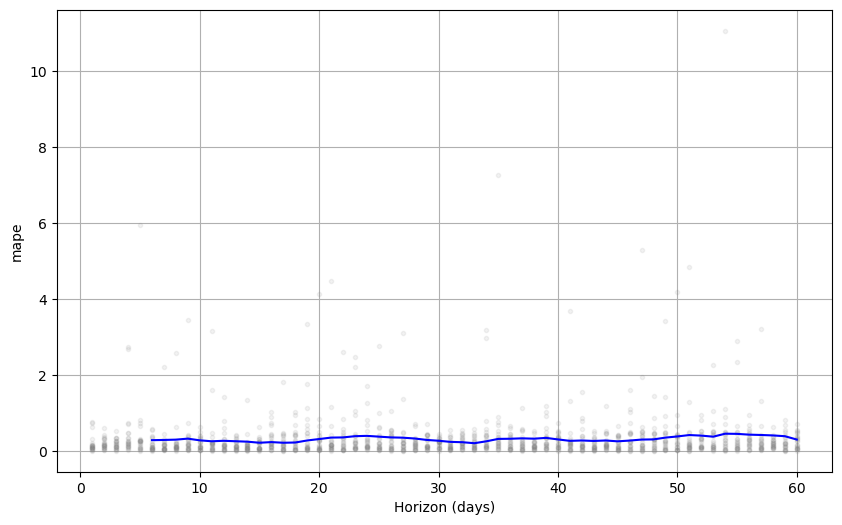

In [94]:
from prophet.plot import plot_cross_validation_metric
fig_mape = plot_cross_validation_metric(cv_results, metric='mape')

The resulting plot shows MAPE across the forecast horizon. A flat line indicates the model is highly stable regardless of how far out it predicts. An upward-trending line means the model degrades quickly and should only be trusted for short-term forecasts (e.g., 7-14 days).

In [98]:
df_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype          
---  ------        --------------  -----          
 0   horizon       55 non-null     timedelta64[ns]
 1   mse           55 non-null     float64        
 2   rmse          55 non-null     float64        
 3   mae           55 non-null     float64        
 4   mape          55 non-null     float64        
 5   mdape         55 non-null     float64        
 6   smape         55 non-null     float64        
 7   coverage      55 non-null     float64        
 8   horizon_days  55 non-null     int64          
dtypes: float64(7), int64(1), timedelta64[ns](1)
memory usage: 4.0 KB


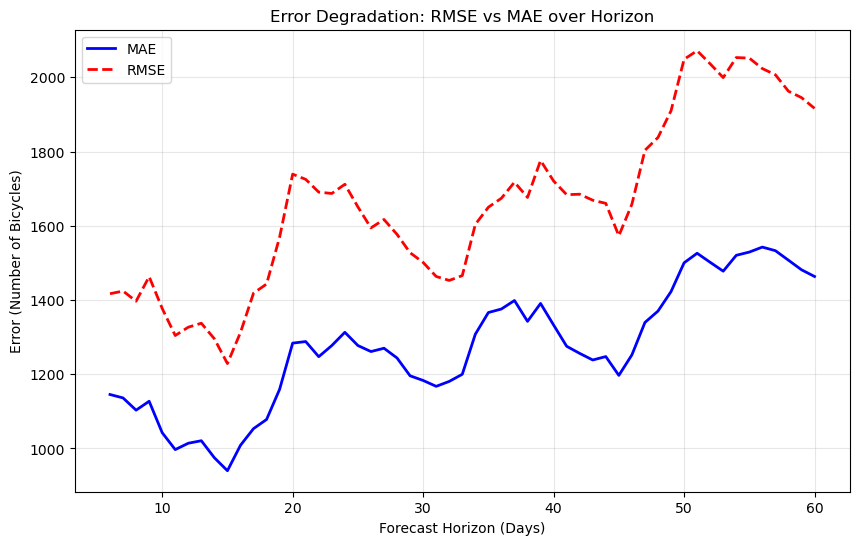

In [ ]:
df_p['horizon_days'] = df_p['horizon'].dt.days

plt.figure(figsize=(10, 6))
plt.plot(df_p['horizon_days'], df_p['mae'], label='MAE', color='blue', linewidth=2)
plt.plot(df_p['horizon_days'], df_p['rmse'], label='RMSE', color='red', linewidth=2, linestyle='--')

plt.title('Error Degradation: RMSE vs MAE over Horizon')
plt.xlabel('Forecast Horizon (Days)')
plt.ylabel('Error (Number of Bicycles)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

* **Does the gap between the red RMSE line and the blue MAE line stay the same, or does it change over time?**
* **In a well-tuned model, errors should increase smoothly over time.** However, both metrics here show clear repeating 'humps' that peak around day 20, day 39, and day 51. This pattern suggests there is a recurring trend in the data that the Prophet model is not capturing. This likely means the current seasonal or regressor settings are out of sync or missing a key cycle that affects results at these times.
* **When should you stop trusting the forecast?** The MAE reaches its lowest point around day 15 (under 1000 bicycles), then quickly rises. In practice, this model is very reliable for forecasts up to two weeks ahead. 

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_50811/4033096599.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='day_of_week', y='ape', data=cv_results, palette='Set2')


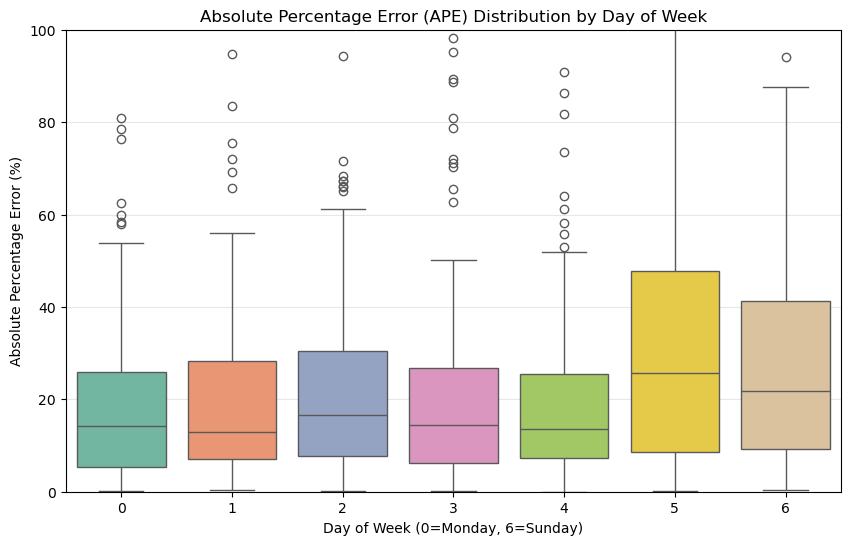

In [100]:
cv_results['ape'] = (abs(cv_results['y'] - cv_results['yhat']) / cv_results['y']) * 100
cv_results['day_of_week'] = cv_results['ds'].dt.dayofweek

plt.figure(figsize=(10, 6))
sns.boxplot(x='day_of_week', y='ape', data=cv_results, palette='Set2')

plt.title('Absolute Percentage Error (APE) Distribution by Day of Week')
plt.xlabel('Day of Week (0=Monday, 6=Sunday)')
plt.ylabel('Absolute Percentage Error (%)')
plt.ylim(0, 100) 
plt.grid(True, alpha=0.3, axis='y')
plt.show()

- **Check the horisontal line inside each box, which represents the typical error for that day(median).** In this chart, weekdays (days 0–4) consistently hover safely under 20%, while the weekend medians (days 5 and 6) jump noticeably higher. This immediately tells us the model struggles fundamentally to understand weekend rider behavior compared to the daily commuter grind.
- **The box height, which represents the Interquartile Range, shows how much the errors usually vary.** From Monday through Friday, the boxes are small, so weekday errors are steady and predictable. On Saturday and Sunday (days 5 and 6), the boxes are much larger, stretching from about 10% to almost 50%. This means the model's accuracy on those days is much less stable.
- **Notice the individual circles above the top whiskers. These show major forecasting errors.** Even though weekdays usually have tight ranges, there are still big outliers with errors as high as 80% to almost 100%. This means the model usually handles weekdays well, but unusual events, such as a sudden thunderstorm on a Wednesday or a public holiday on a Tuesday, can throw off the predictions completely.

We need to rethink the flexibility of the weekend seasonality to shrink those massive boxes and map those weekday outlier dots to a calendar to see whether they align with missing holiday or weather regressors.

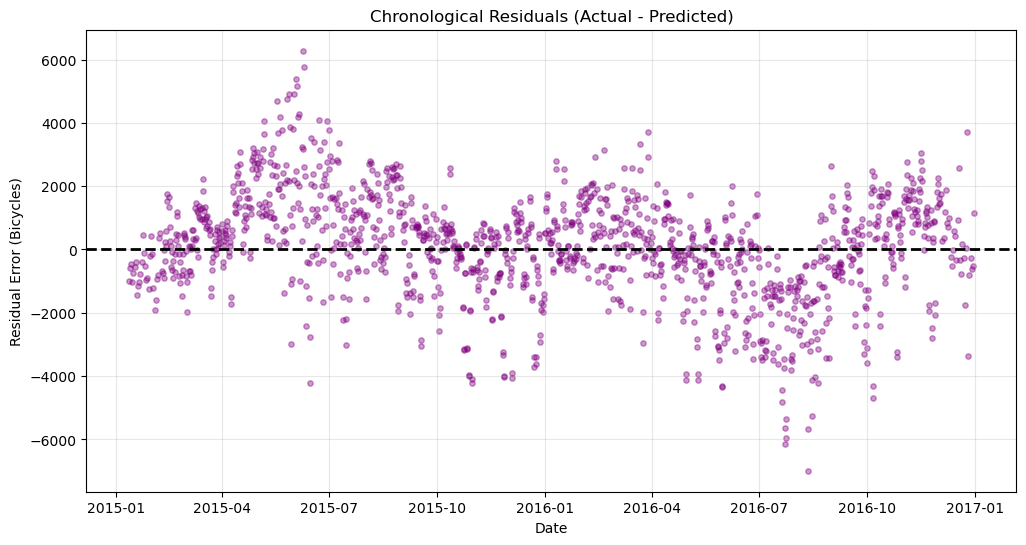

In [ ]:
plt.figure(figsize=(12, 6))
plt.scatter(cv_results['ds'], cv_results['errors'], alpha=0.4, color='purple', s=15)
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)

plt.title('Chronological Residuals (Actual - Predicted)')
plt.xlabel('Date')
plt.ylabel('Residual Error (Bicycles)')
plt.grid(True, alpha=0.3)
plt.show()

A healthy model should output a random cloud of static centred tightly around the dashed zero line.

From April to August 2015, the residuals show a large spike above the zero line, reaching almost +6,000 bicycles. Since residual error is actual minus predicted, these positive values show the model greatly underestimated demand. The model completely missed a major jump in ridership during this time, likely caused by something like a fleet expansion, a new pricing model, or a competitor leaving the market.

In contrast, during the summer of 2016, especially from July to September, the residuals drop sharply to -7,000. The model expected the big summer growth from 2015 to happen again or even increase, but actual ridership was much lower.

During the winter months (Jan 2015, Jan 2016, Jan 2017), the errors stay close to the zero line. In contrast, the purple dots spread out much more during the summer months. The model's error margin grows a lot during busy periods. Using a simple multiplicative seasonality setting does not reflect the real changes in summer peaks.

##### Recommendations to improve the model:

1. **Help the model adapt to trends more quickly**

Large gaps in the residuals show that the trend line is several months behind what is actually happening. Try increasing the changepoint_prior_scale (for example, from 0.05 to 0.1 or 0.2) so the model can respond more quickly to big changes in summer volume. You can also manually add changepoint dates at the start of the 2015 surge and the 2016 crash.

2. **Add precipitation as a regressor(suppose we have access to a weather API)**

Average temperature alone does not explain the large weekday errors, which can be over 80%. Even on a mild Tuesday, there may be no bike commuters if it is raining heavily. Add binary regressors for is_raining or is_snowing, or use a continuous regressor for precipitation in inches. This should help reduce those weekday anomaly spikes.

3. **Separate weekend seasonality**

The large errors on Saturdays and Sundays show that the current Fourier terms cannot capture the difference between commuter and weekend leisure riding. Create a custom binary column (is_weekend) and set up a new seasonality component based on it. This lets Prophet learn a separate pattern for weekends.

4. **Use a log transformation**

The residuals show a lot of variation, especially during the busy summer months. If using seasonality_mode='multiplicative' does not solve this, try applying a log transformation to the target variable ($y = \log(y)$) before fitting. This helps the model predict percentage changes and keeps the variance steady in both winter and summer.
